# Storing a network, measuring distances in it, and why the queue matters

A graph is a set of vertices and a set of edges. In this session we learned two
ways to store one, namely the adjacency matrix and the adjacency list, and one
algorithm to explore one, namely breadth-first search. This notebook shows why
the choice of representation decides whether a social network fits in memory at
all, and why the queue inside BFS is necessary to find shortest paths.

## 1. Matrix or list?

A social network of $n$ people with about $k$ friends each has $nk/2$ edges.
The adjacency matrix has $n^2$ entries whether they are 0 or 1, while the
adjacency list stores only the edges. We build both for a small random network
and measure them. Then we scale the numbers up.

In [2]:
import random
import numpy as np

def random_network(n, k, seed=5):
    # undirected graph with n vertices and about k neighbors each, as adjacency lists
    rnd = random.Random(seed)
    neighbors = [[] for _ in range(n)]
    for _ in range(n * k // 2):
        u, v = rnd.randrange(n), rnd.randrange(n)
        if u != v and v not in neighbors[u]:
            neighbors[u].append(v); neighbors[v].append(u)
    return neighbors

n, k = 5_000, 10
adj_list = random_network(n, k)
adj_matrix = np.zeros((n, n), dtype=np.int8)               # one byte per entry
for u, nbrs in enumerate(adj_list):
    adj_matrix[u, nbrs] = 1

edges = sum(len(x) for x in adj_list) // 2
print(f"{n} people, {edges} friendships")
print(f"matrix: {adj_matrix.nbytes / 1e6:8.1f} MB   ({n} x {n} entries, almost all 0)")
print(f"lists:  {edges * 2 * 8 / 1e6:8.1f} MB   ({edges * 2} neighbor entries at 8 bytes)")

5000 people, 24974 friendships
matrix:     25.0 MB   (5000 x 5000 entries, almost all 0)
lists:       0.4 MB   (49948 neighbor entries at 8 bytes)


For 5,000 people the matrix is 25 MB and the lists are under a megabyte.
Now we scale the numbers up, knowing that the matrix grows with $n^2$ and the
lists with $nk$.

In [3]:
for people in [5_000, 100_000, 2_000_000]:
    matrix_gb = people ** 2 / 1e9
    lists_gb = people * k * 8 / 1e9
    print(f"{people:>10} people   matrix {matrix_gb:10.1f} GB   lists {lists_gb:8.3f} GB")

      5000 people   matrix        0.0 GB   lists    0.000 GB
    100000 people   matrix       10.0 GB   lists    0.008 GB
   2000000 people   matrix     4000.0 GB   lists    0.160 GB


At 100,000 people, which is a mid-sized online community, the matrix needs
10 GB at one byte per entry and 80 GB with the 8-byte numbers that `np.zeros`
uses by default. This is more than most laptops have, while the lists need 8 MB.
At two million people the matrix would take 4 terabytes. Real social networks
are sparse, i.e. each person knows a few hundred of the millions of people, and
the representation has to exploit that or the analysis cannot even start.

The matrix is still useful for some questions. Asking "are $u$ and $v$
friends?" is one lookup in the matrix and a scan of a short list in the
adjacency list. Listing the friends of $u$ is the opposite, i.e. a row of $n$
entries in the matrix and a list of $k$ in the adjacency list. Which one you
need depends on the questions you ask most.

In [4]:
import time

u = 17
t0 = time.perf_counter()
for _ in range(1000):
    friends_m = np.flatnonzero(adj_matrix[u])        # scan a row of n entries
t_matrix = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(1000):
    friends_l = adj_list[u]                          # already a list of k
t_list = time.perf_counter() - t0
print(f"friends of {u}: {sorted(friends_l)}")
print(f"1000 times 'list the friends': matrix {t_matrix * 1000:.1f} ms, lists {t_list * 1000:.3f} ms")

friends of 17: [818, 1417, 1716, 3162, 4746]
1000 times 'list the friends': matrix 9.1 ms, lists 0.077 ms


## 2. Breadth-first search and the six degrees

BFS finds the distance from one person to everyone else in hops. The version of
this session keeps the vertices that are waiting to be processed in a queue,
i.e. first in, first out. Here we implement it with a `deque`, run it from one
person in the network of 5,000 people and plot the resulting distances.

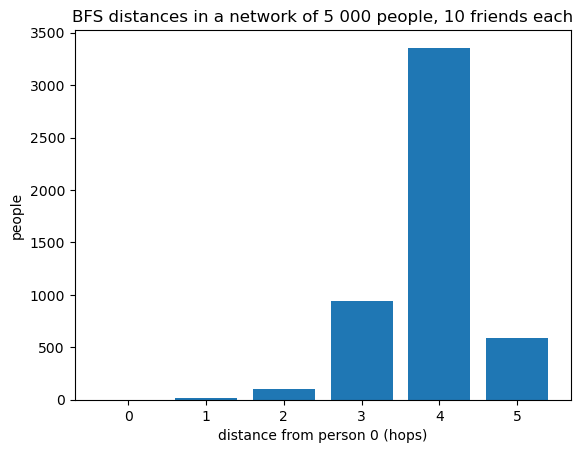

reached 5000 of 5000; mean distance 3.88, maximum 5


In [5]:
from collections import deque
import matplotlib.pyplot as plt

def bfs(neighbors, source):
    distance = [None] * len(neighbors)
    distance[source] = 0
    queue = deque([source])
    while queue:
        u = queue.popleft()                 # take the oldest vertex in the queue
        for v in neighbors[u]:
            if distance[v] is None:         # WHITE: not seen yet
                distance[v] = distance[u] + 1
                queue.append(v)
    return distance

dist = bfs(adj_list, 0)
reached = [d for d in dist if d is not None]
plt.hist(reached, bins=range(max(reached) + 2), align="left", rwidth=0.8)
plt.xlabel("distance from person 0 (hops)"); plt.ylabel("people")
plt.title("BFS distances in a network of 5 000 people, 10 friends each")
plt.show()
print(f"reached {len(reached)} of {n}; mean distance {np.mean(reached):.2f}, maximum {max(reached)}")

Almost everyone is within four or five hops of person 0, even though each
person knows only ten others. The reason is that the number of people at
distance $d$ grows roughly like $10^d$ until there are no more people left in
the network. This is the small-world effect, and BFS is the algorithm behind
the "degrees of separation" numbers that you may have read.

## 3. Why a queue and not a stack

The only difference between BFS and depth-first search is the container,
because BFS takes the oldest vertex and DFS the newest. If we change
`popleft()` to `pop()`, the search still reaches everyone but the distances
that it records are no longer the shortest.

In [6]:
def stack_search(neighbors, source):
    distance = [None] * len(neighbors)
    distance[source] = 0
    stack = [source]
    while stack:
        u = stack.pop()                     # take the newest vertex instead
        for v in neighbors[u]:
            if distance[v] is None:
                distance[v] = distance[u] + 1
                stack.append(v)
    return distance

dist_stack = stack_search(adj_list, 0)
longer = sum(1 for a, b in zip(dist, dist_stack) if a is not None and b > a)
print(f"reached with the stack: {sum(d is not None for d in dist_stack)} of {n}")
print(f"people whose recorded distance is longer than the true one: {longer}")
print(f"largest recorded distance: BFS {max(reached)}, stack {max(d for d in dist_stack if d is not None)}")

reached with the stack: 5000 of 5000
people whose recorded distance is longer than the true one: 4963
largest recorded distance: BFS 5, stack 922


With the stack the search goes deep before it looks at the other neighbors,
so it reaches most people by a long chain and records distances in the hundreds
where the true distance is four or five. The graph is the same and the code
differs in only one method call, but the answer to "how far apart are two
people?" is wrong for nearly everyone. The correctness of BFS therefore depends
on the queue and not only on the loop.

**What we used:** [representing graphs](https://dgarcia-eu.github.io/ICSS/Transcripts/05-Algorithms.html#representing-graphs-in-a-computer),
[queues and stacks](https://dgarcia-eu.github.io/ICSS/Transcripts/05-Algorithms.html#abstract-data-structures) and
[breadth-first search](https://dgarcia-eu.github.io/ICSS/Transcripts/05-Algorithms.html#breadth-first-search) from this session.